In [1]:
## ============================================================
## CELL 0: INSTALL DEPENDENCIES (RUN ONCE)
## ============================================================

## Purpose: Install these packages only when they are missing from your notebook environment.
## %pip install -q sentence-transformers transformers torch scikit-learn numpy pandas matplotlib
## Optional (faster exact/approximate index):
## %pip install -q faiss-cpu
print('Use the commented installation commands only if your environment needs them.')

Use the commented installation commands only if your environment needs them.


In [3]:
# ============================================================
# CELL 1: IMPORTS AND REPRODUCIBLE WORKSPACE
# ============================================================

# Purpose: Import tools, fix random seeds, pick a device, and create one output folder.

from pathlib import Path
import json, re, time, random, pickle, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Markdown
from sentence_transformers import SentenceTransformer

warnings.filterwarnings('ignore')

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

try:
    import faiss
    HAS_FAISS = True
except ImportError:
    HAS_FAISS = False

DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')

ROOT = Path('rag_outputs')
ROOT.mkdir(exist_ok=True)
pd.set_option('display.max_colwidth', 160)
np.set_printoptions(precision=4, suppress=True)

print('Device:', DEVICE, '| FAISS available:', HAS_FAISS)
print('Output folder:', ROOT.resolve())

Device: mps | FAISS available: False
Output folder: /Users/afrillianramadhan/Documents/ACADEMIC/COURSES/INFO_490_WEB_AI_DEV/GreenHand/llm-test/rag_outputs


In [4]:
# ============================================================
# CELL 2: EXPERIMENT CONFIGURATION (ONE PLACE FOR ALL SETTINGS)
# ============================================================

# --- Embedding models (Hugging Face sentence-transformers, free to use) -------------
# Size tiers are defined by output dimension. E5 models need "query:" / "passage:" prefixes.
EMBEDDING_MODELS = {
    'small':  {'name': 'sentence-transformers/all-MiniLM-L6-v2',  'query_prefix': '',        'passage_prefix': ''},
    'medium': {'name': 'sentence-transformers/all-mpnet-base-v2', 'query_prefix': '',        'passage_prefix': ''},
    'large':  {'name': 'intfloat/e5-large-v2',                    'query_prefix': 'query: ', 'passage_prefix': 'passage: '},
}

# --- Generation model from A6/A7 -------------------------------------------------------
# TODO (team): replace with the generative model your team evaluated in A6 or A7.
# This SAME model is used for every experiment; only the embeddings and chunking change.
GEN_BACKEND = 'hf'                              # 'hf' = local transformers, 'ollama' = local Ollama server
GEN_MODEL_NAME = 'Qwen/Qwen2.5-3B-Instruct'   # e.g. 'Qwen/Qwen2.5-0.5B-Instruct', 'google/flan-t5-base', 'llama3.2:3b' (ollama)
GEN_MAX_NEW_TOKENS = 200
OLLAMA_URL = 'http://localhost:11434/api/chat'

# TODO (team): one line describing your knowledge base (used in the system prompt).
KB_DESCRIPTION = 'our project knowledge base'

# --- Retrieval ---------------------------------------------------------------------------
TOP_K = 3

# --- Chunking ----------------------------------------------------------------------------
FIXED_CHUNK_WORDS = 120          # fixed-length budget (whole sentences only)
OVERLAP_WINDOW, OVERLAP_STRIDE = 2, 1   # P1+P2, P2+P3, ...
HYBRID_MIN_WORDS = 60            # paragraphs shorter than this are candidates for merging
HYBRID_MAX_WORDS = 220           # paragraphs longer than this are split at a topic shift
HYBRID_MERGE_SIM = 0.70          # merge any two adjacent same-section units this similar
HYBRID_SHORT_MERGE_SIM = 0.40    # lower bar for merging a short unit into its neighbour

print('Generation model (fixed for all experiments):', GEN_MODEL_NAME)
display(pd.DataFrame([{'tier': t, **c} for t, c in EMBEDDING_MODELS.items()]))

Generation model (fixed for all experiments): Qwen/Qwen2.5-3B-Instruct


,tier,name,query_prefix,passage_prefix
0,small,sentence-transformers/all-MiniLM-L6-v2,,
1,medium,sentence-transformers/all-mpnet-base-v2,,
2,large,intfloat/e5-large-v2,query:,passage:


In [11]:
# ============================================================
# CELL 3: >>> DATA PLACEHOLDER: PUT YOUR KNOWLEDGE BASE HERE <<<
# ============================================================

# TODO (team): choose ONE option.
#
# Option A (recommended): put your file next to this notebook and set its path.
DATA_PATH = 'home-gardening-guide-en.md'         # e.g. 'data/knowledge_base.txt'  or  'data/knowledge_base.csv'
#
# Option B: leave DATA_PATH = None and paste the document text below.
#   - Separate paragraphs with ONE BLANK LINE.
#   - Optional: start a line with '#' to mark a section heading.
DOCUMENT_TEXT = """
# <<SECTION TITLE (optional)>>
<<PASTE YOUR PARAGRAPH 1 HERE (about 80-200 words)>>

<<PASTE YOUR PARAGRAPH 2 HERE>>

# <<ANOTHER SECTION TITLE>>
<<PASTE YOUR PARAGRAPH 3 HERE>>
"""

# Optional, for Step 2.5 (data scaling): an ADDITIONAL file that makes the corpus larger
# (same format as above, e.g. more documents from the same domain). Leave None to skip.
EXTRA_DATA_PATH = None      # e.g. 'data/extra_documents.txt'

In [12]:
# ============================================================
# CELL 4: LOAD THE DOCUMENTS AND DEFINE PARAGRAPHS
# ============================================================

# Purpose: Turn the raw document(s) into one table of paragraphs with IDs and sections.
# A "paragraph" = a block of text separated from the next one by a blank line.

PLACEHOLDER_MARKER = 'home-gardening-guide-en.md'

def _clean(s):
    return re.sub(r'\s+', ' ', str(s)).strip()

def parse_text_document(raw, default_section='Document'):
    """Blank line = paragraph boundary; a line starting with '#' = section heading."""
    rows, buf, section = [], [], default_section
    for line in raw.splitlines() + ['']:
        s = line.strip()
        if s.startswith('#') or not s:
            if buf:
                rows.append({'section': section, 'text': _clean(' '.join(buf))})
                buf = []
            if s.startswith('#'):
                section = s.lstrip('#').strip() or default_section
        else:
            buf.append(s)
    return rows

def parse_table(df):
    """One row per document/paragraph; rows that contain blank lines are split into paragraphs."""
    text_col = next((c for c in ['text', 'content', 'paragraph', 'body'] if c in df.columns), None)
    if text_col is None:
        raise ValueError(f'No text column found. Columns: {list(df.columns)}')
    sec_col = next((c for c in ['section', 'title', 'topic', 'heading'] if c in df.columns), None)
    rows = []
    for i, r in df.reset_index(drop=True).iterrows():
        section = _clean(r[sec_col]) if sec_col else f'Document {i + 1}'
        for para in re.split(r'\n\s*\n', str(r[text_col])):
            if _clean(para):
                rows.append({'section': section, 'text': _clean(para)})
    return rows

def load_knowledge_base(path=None, inline_text=None, pid_prefix='P'):
    if path:
        p = Path(path)
        if not p.exists():
            raise FileNotFoundError(f'{p.resolve()} does not exist. Check DATA_PATH in CELL 3.')
        suffix = p.suffix.lower()
        if suffix in ('.txt', '.md'):
            rows = parse_text_document(p.read_text(encoding='utf-8'))
        elif suffix == '.csv':
            rows = parse_table(pd.read_csv(p))
        elif suffix in ('.json', '.jsonl'):
            rows = parse_table(pd.read_json(p, lines=(suffix == '.jsonl')))
        else:
            raise ValueError(f'Unsupported file type {suffix}. Convert to .txt, .md, .csv or .json.')
    else:
        if not inline_text or PLACEHOLDER_MARKER in inline_text:
            raise ValueError('Fill in the DATA PLACEHOLDER in CELL 3 (DATA_PATH or DOCUMENT_TEXT) first.')
        rows = parse_text_document(inline_text)
    kb = pd.DataFrame(rows)
    kb.insert(0, 'pid', [f'{pid_prefix}{i + 1:03d}' for i in range(len(kb))])
    kb['n_words'] = kb['text'].str.split().str.len()
    return kb

kb = load_knowledge_base(DATA_PATH, DOCUMENT_TEXT)
print(f'Loaded {len(kb)} paragraphs in {kb["section"].nunique()} section(s).')
display(kb.head(10))

Loaded 59 paragraphs in 16 section(s).


,pid,section,text,n_words
0,P001,Large Yard,"In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*vertikultur*). With a large yard, we have more ...",42
1,P002,Small Yard,"Having a small yard is no barrier to growing vegetables at home. There are many things you can do, including using growing containers such as pots, polybags...",30
2,P003,Beds (*Bedengan*),"Hoe the soil to a depth of 20–30 cm and apply manure at 1 kg/m². Level the soil, then form planting beds 60 cm or 1 m wide, with the length adjusted to the ...",38
3,P004,Pots and Polybags,"- Choose the type and size (diameter) of pot or polybag to suit the plant being grown. - For perennial plants, generally fruit plants, choose a pot made fro...",61
4,P005,Pots and Polybags,Plants that can be grown in pots and polybags include:,10
5,P006,Pots and Polybags,"1. Several kinds of fruit, known as *Tabulampot* (fruit plants in pots), for example: water apple, bell apple, sapodilla, mango, citrus, etc. 2. Fruiting ve...",49
6,P007,VERTICAL GARDENING (*VERTIKULTUR*),Vertical gardening is a method of growing in which the growing medium is placed in containers arranged vertically. Growing with a vertical system can be an ...,44
7,P008,VERTICAL GARDENING (*VERTIKULTUR*),(1) Rack: this type can be made from gutters and bamboo assembled into a rack.,15
8,P009,VERTICAL GARDENING (*VERTIKULTUR*),"(2) Tube: this type can be made from plastic materials (drums, bamboo, and PVC pipes).",15
9,P010,GROWING MEDIUM,Preparing Seedlings:,2


,requirement,value,status
0,"Number of paragraphs (min 20, recommended 30-50)",59,PASS
1,Share of paragraphs with 80-200 words,8%,CHECK
2,"Total words (at least 2,000-5,000)","2,422",PASS


Paragraph length: min 2 | mean 41.1 | max 166


,paragraphs,words
section,,
Large Yard,1,42
Small Yard,1,30
Beds (*Bedengan*),1,38
Pots and Polybags,3,120
VERTICAL GARDENING (*VERTIKULTUR*),3,74
GROWING MEDIUM,7,221
CULTIVATION TECHNIQUES,8,245
(Small yard),2,84
(Large yard),2,164


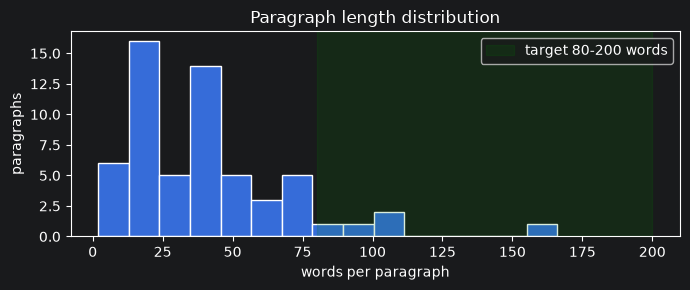

Paragraphs outside 80-200 words (consider editing the source):


,pid,section,n_words
0,P001,Large Yard,42
1,P002,Small Yard,30
2,P003,Beds (*Bedengan*),38
3,P004,Pots and Polybags,61
4,P005,Pots and Polybags,10
5,P006,Pots and Polybags,49
6,P007,VERTICAL GARDENING (*VERTIKULTUR*),44
7,P008,VERTICAL GARDENING (*VERTIKULTUR*),15
8,P009,VERTICAL GARDENING (*VERTIKULTUR*),15
9,P010,GROWING MEDIUM,2


In [13]:
# ============================================================
# CELL 5: CHECK THE DATASET SIZE REQUIREMENTS
# ============================================================

# Purpose: Verify paragraph count, paragraph length and total size against the assignment rules.

n_par, total_words = len(kb), int(kb['n_words'].sum())
in_range = kb['n_words'].between(80, 200).mean()
checks = pd.DataFrame([
    {'requirement': 'Number of paragraphs (min 20, recommended 30-50)', 'value': n_par,
     'status': 'PASS' if n_par >= 20 else 'FAIL'},
    {'requirement': 'Share of paragraphs with 80-200 words', 'value': f'{in_range:.0%}',
     'status': 'PASS' if in_range >= 0.8 else 'CHECK'},
    {'requirement': 'Total words (at least 2,000-5,000)', 'value': f'{total_words:,}',
     'status': 'PASS' if total_words >= 2000 else 'FAIL'},
])
display(checks)
print('Paragraph length: min', kb.n_words.min(), '| mean', round(kb.n_words.mean(), 1), '| max', kb.n_words.max())
display(kb.groupby('section', sort=False).agg(paragraphs=('pid', 'count'), words=('n_words', 'sum')))

plt.figure(figsize=(7, 3))
plt.hist(kb['n_words'], bins=15, edgecolor='white')
plt.axvspan(80, 200, alpha=0.15, color='green', label='target 80-200 words')
plt.xlabel('words per paragraph'); plt.ylabel('paragraphs'); plt.legend(); plt.title('Paragraph length distribution')
plt.tight_layout(); plt.show()

outliers = kb[~kb['n_words'].between(80, 200)]
if len(outliers):
    print('Paragraphs outside 80-200 words (consider editing the source):')
    display(outliers[['pid', 'section', 'n_words']])

In [14]:
# ============================================================
# CELL 6: SENTENCE SPLITTER AND CHUNK HELPERS
# ============================================================

# Purpose: Split text into whole sentences without breaking common abbreviations.

_ABBREVIATIONS = ['e.g.', 'i.e.', 'etc.', 'vs.', 'Dr.', 'Mr.', 'Mrs.', 'Ms.', 'Prof.', 'Inc.', 'Ltd.',
                  'Jr.', 'Sr.', 'St.', 'No.', 'Fig.', 'U.S.', 'U.K.', 'a.m.', 'p.m.', 'approx.']
_SENT_RE = re.compile(r"(?:(?<=[.!?])|(?<=[.!?][\"')\]]))\s+(?=[\"'(\[]?[A-Z0-9])")

def split_sentences(text):
    protected = text
    for a in _ABBREVIATIONS:
        protected = protected.replace(a, a.replace('.', '<DOT>'))
    return [s.replace('<DOT>', '.').strip() for s in _SENT_RE.split(protected) if s.strip()]

def make_chunk(strategy, sents, section, pids, header=''):
    body = ' '.join(sents)
    return {'strategy': strategy, 'section': section, 'pids': list(dict.fromkeys(pids)),
            'sents': list(sents), 'body': body, 'text': (header + body) if header else body,
            'n_words': len(body.split())}

def number_chunks(chunks, prefix):
    for i, c in enumerate(chunks, 1):
        c['chunk_id'] = f'{prefix}-{i:03d}'
    return chunks

print(split_sentences('Dr. Lee wrote this, e.g. as a test. It has two sentences! Does it? Yes.'))

['Dr. Lee wrote this, e.g. as a test.', 'It has two sentences!', 'Does it?', 'Yes.']


In [15]:
# ============================================================
# CELL 7: THREE CHUNKING STRATEGIES
# ============================================================

def fixed_length_chunks(kb, max_words=FIXED_CHUNK_WORDS):
    """Pack whole sentences into chunks of at most max_words words, within one section."""
    chunks = []
    for section, grp in kb.groupby('section', sort=False):
        cur, cur_pids, cur_n = [], [], 0
        for _, row in grp.iterrows():
            for sent in split_sentences(row['text']):
                n = len(sent.split())
                if cur and cur_n + n > max_words:
                    chunks.append(make_chunk('fixed', cur, section, cur_pids))
                    cur, cur_pids, cur_n = [], [], 0
                cur.append(sent); cur_pids.append(row['pid']); cur_n += n
        if cur:
            chunks.append(make_chunk('fixed', cur, section, cur_pids))
    return number_chunks(chunks, 'FIX')


def overlapping_paragraph_chunks(kb, window=OVERLAP_WINDOW, stride=OVERLAP_STRIDE):
    """Sliding window over adjacent paragraphs: P1+P2, P2+P3, ... within one section."""
    chunks = []
    for section, grp in kb.groupby('section', sort=False):
        rows = grp.to_dict('records')
        last_start = max(len(rows) - window, 0)
        starts = list(range(0, last_start + 1, stride))
        if starts[-1] != last_start:          # make sure the tail paragraphs are covered
            starts.append(last_start)
        for s in starts:
            win = rows[s:s + window]
            sents = [x for r in win for x in split_sentences(r['text'])]
            chunks.append(make_chunk('overlap', sents, section, [r['pid'] for r in win]))
    return number_chunks(chunks, 'OVL')


def _semantic_split(sents, encoder, max_words):
    """Recursively split a long sentence list at the weakest link between consecutive sentences."""
    if len(' '.join(sents).split()) <= max_words or len(sents) < 2:
        return [sents]
    vecs = encoder.encode(sents, normalize_embeddings=True, show_progress_bar=False)
    sims = (vecs[:-1] * vecs[1:]).sum(axis=1)       # similarity of sentence i and i+1
    cut = int(np.argmin(sims)) + 1
    return _semantic_split(sents[:cut], encoder, max_words) + _semantic_split(sents[cut:], encoder, max_words)


def hybrid_chunks(kb, encoder, min_words=HYBRID_MIN_WORDS, max_words=HYBRID_MAX_WORDS,
                  merge_sim=HYBRID_MERGE_SIM, short_merge_sim=HYBRID_SHORT_MERGE_SIM):
    """Paragraph structure + semantic split/merge + section header."""
    # (a) paragraphs as units; split over-long paragraphs at the topic shift
    units = []
    for _, row in kb.iterrows():
        for piece in _semantic_split(split_sentences(row['text']), encoder, max_words):
            units.append({'section': row['section'], 'sents': piece, 'pids': [row['pid']]})
    # (b) merge adjacent, related units inside the same section
    vecs = encoder.encode([' '.join(u['sents']) for u in units], normalize_embeddings=True, show_progress_bar=False)
    merged = []
    for u, v in zip(units, vecs):
        if merged:
            prev = merged[-1]
            n_prev, n_u = len(' '.join(prev['sents']).split()), len(' '.join(u['sents']).split())
            sim = float(prev['vec'] @ v)
            related = sim >= merge_sim or (min(n_prev, n_u) < min_words and sim >= short_merge_sim)
            if prev['section'] == u['section'] and n_prev + n_u <= max_words and related:
                prev['sents'] += u['sents']; prev['pids'] += u['pids']
                prev['vec'] = (prev['vec'] + v) / np.linalg.norm(prev['vec'] + v)
                continue
        merged.append({**u, 'sents': list(u['sents']), 'pids': list(u['pids']), 'vec': v})
    # (c) prepend the section title as a contextual header (only when sections exist)
    use_header = kb['section'].nunique() > 1
    chunks = [make_chunk('hybrid', m['sents'], m['section'], m['pids'],
                         header=f"[{m['section']}] " if use_header else '') for m in merged]
    return number_chunks(chunks, 'HYB')

print('Chunking functions ready.')

Chunking functions ready.


In [16]:
# ============================================================
# CELL 8: BUILD THE CHUNKS AND COMPARE THEM
# ============================================================

def get_encoder(tier, _cache={}):
    """Load each embedding model once and reuse it."""
    name = EMBEDDING_MODELS[tier]['name']
    if name not in _cache:
        _cache[name] = SentenceTransformer(name, device=DEVICE)
    return _cache[name]

CHUNKERS = {
    'fixed':   lambda data: fixed_length_chunks(data),
    'overlap': lambda data: overlapping_paragraph_chunks(data),
    'hybrid':  lambda data: hybrid_chunks(data, get_encoder('small')),
}
CHUNK_STRATEGIES = list(CHUNKERS)
CHUNKS = {name: fn(kb) for name, fn in CHUNKERS.items()}

chunk_stats = pd.DataFrame([{
    'strategy': name, 'n_chunks': len(ch),
    'mean_words': round(np.mean([c['n_words'] for c in ch]), 1),
    'min_words': min(c['n_words'] for c in ch), 'max_words': max(c['n_words'] for c in ch),
    'mean_paragraphs_per_chunk': round(np.mean([len(c['pids']) for c in ch]), 2),
} for name, ch in CHUNKS.items()])
display(chunk_stats)

for name, ch in CHUNKS.items():
    print(f'\n=== {name.upper()}: first 3 chunks ===')
    for c in ch[:3]:
        print(f"{c['chunk_id']} | paragraphs {c['pids']} | {c['n_words']} words\n  {c['text'][:300]}{'...' if len(c['text']) > 300 else ''}")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2133.57it/s, Materializing param=pooler.dense.weight]                             
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,strategy,n_chunks,mean_words,min_words,max_words,mean_paragraphs_per_chunk
0,fixed,31,78.1,30,120,2.19
1,overlap,49,76.2,16,186,1.88
2,hybrid,52,46.6,10,166,1.13



=== FIXED: first 3 chunks ===
FIX-001 | paragraphs ['P001'] | 42 words
  In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*vertikultur*). With a large yard, we have more freedom to grow plants at home. Options include: in-ground beds, which can be combined with pots, polybags, and vertical gardening.
FIX-002 | paragraphs ['P002'] | 30 words
  Having a small yard is no barrier to growing vegetables at home. There are many things you can do, including using growing containers such as pots, polybags, and vertical gardening.
FIX-003 | paragraphs ['P003'] | 38 words
  Hoe the soil to a depth of 20–30 cm and apply manure at 1 kg/m². Level the soil, then form planting beds 60 cm or 1 m wide, with the length adjusted to the condition of the land.

=== OVERLAP: first 3 chunks ===
OVL-001 | paragraphs ['P001'] | 42 words
  In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*vertik

In [17]:
# ============================================================
# CELL 9: VERIFY THE CHUNKING RULES
# ============================================================

# Purpose: Prove that (1) every chunk contains only whole, original sentences and
# (2) no chunk mixes paragraphs from different sections.

original_sentences = {s for t in kb['text'] for s in split_sentences(t)}
pid_to_section = dict(zip(kb['pid'], kb['section']))

rows = []
for name, ch in CHUNKS.items():
    broken = sum(s not in original_sentences for c in ch for s in c['sents'])
    mixed = sum(len({pid_to_section[p] for p in c['pids']}) > 1 for c in ch)
    covered = {p for c in ch for p in c['pids']}
    rows.append({'strategy': name, 'split/altered sentences': broken, 'chunks mixing sections': mixed,
                 'paragraphs covered': f'{len(covered)}/{len(kb)}',
                 'status': 'PASS' if broken == 0 and mixed == 0 and len(covered) == len(kb) else 'CHECK'})
display(pd.DataFrame(rows))

,strategy,split/altered sentences,chunks mixing sections,paragraphs covered,status
0,fixed,0,0,59/59,PASS
1,overlap,0,0,59/59,PASS
2,hybrid,0,0,59/59,PASS


In [18]:
# ============================================================
# CELL 10: VECTOR STORE AND THE 9 INDEXES (3 MODELS x 3 CHUNKINGS)
# ============================================================

class VectorStore:
    """Searchable structure: normalised chunk vectors + metadata (cosine similarity = dot product)."""

    def __init__(self, tier, strategy, chunks):
        self.tier, self.strategy, self.chunks = tier, strategy, chunks
        self.cfg, self.encoder = EMBEDDING_MODELS[tier], get_encoder(tier)
        start = time.perf_counter()
        passages = [self.cfg['passage_prefix'] + c['text'] for c in chunks]
        self.vectors = self.encoder.encode(passages, batch_size=32, normalize_embeddings=True,
                                           convert_to_numpy=True, show_progress_bar=False).astype('float32')
        self.build_s = time.perf_counter() - start
        self.index = None
        if HAS_FAISS:
            self.index = faiss.IndexFlatIP(self.vectors.shape[1])
            self.index.add(self.vectors)

    @property
    def dim(self):
        return self.vectors.shape[1]

    def embed_query(self, query):
        return self.encoder.encode([self.cfg['query_prefix'] + query], normalize_embeddings=True,
                                   convert_to_numpy=True, show_progress_bar=False)[0].astype('float32')

    def search(self, query, k=TOP_K):
        """Query -> embedding -> similarity search -> top-k chunks. Returns (hits, milliseconds)."""
        start = time.perf_counter()
        qv = self.embed_query(query)
        k = min(k, len(self.chunks))
        if self.index is not None:
            scores, idx = self.index.search(qv[None, :], k)
            pairs = list(zip(idx[0], scores[0]))
        else:
            sims = self.vectors @ qv
            top = np.argsort(-sims)[:k]
            pairs = [(i, sims[i]) for i in top]
        ms = (time.perf_counter() - start) * 1000
        hits = [{'rank': r + 1, 'score': float(s), 'chunk_id': self.chunks[i]['chunk_id'],
                 'pids': self.chunks[i]['pids'], 'section': self.chunks[i]['section'],
                 'text': self.chunks[i]['text']} for r, (i, s) in enumerate(pairs)]
        return hits, ms

    def save(self, folder):
        stem = Path(folder) / f'{self.tier}_{self.strategy}'
        np.savez_compressed(f'{stem}.npz', vectors=self.vectors, chunk_ids=[c['chunk_id'] for c in self.chunks])
        meta = [{k: c[k] for k in ('chunk_id', 'section', 'pids', 'text')} for c in self.chunks]
        Path(f'{stem}.json').write_text(json.dumps({'model': self.cfg['name'], 'chunks': meta}, indent=1))


VECTOR_DIR = ROOT / 'vectors'; VECTOR_DIR.mkdir(exist_ok=True)
STORES = {}
for tier in EMBEDDING_MODELS:
    for strategy in CHUNK_STRATEGIES:
        store = VectorStore(tier, strategy, CHUNKS[strategy])
        store.save(VECTOR_DIR)
        STORES[(tier, strategy)] = store

store_table = pd.DataFrame([{
    'embedding': t, 'model': s.cfg['name'].split('/')[-1], 'dims': s.dim, 'chunking': st,
    'n_chunks': len(s.chunks), 'embed_time_s': round(s.build_s, 2),
    'index_KB': round(s.vectors.nbytes / 1024, 1),
} for (t, st), s in STORES.items()])
display(store_table)
print('Example stored vector (small/hybrid, first 8 dims):', STORES[('small', 'hybrid')].vectors[0, :8])

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2634.26it/s, Materializing param=pooler.dense.weight]                        
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Loading weights: 100%|██████████| 391/391 [00:00<00:00, 2106.12it/s, Materializing param=pooler.dense.weight]                               
BertModel LOAD REPORT from: intfloat/e5-large-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,embedding,model,dims,chunking,n_chunks,embed_time_s,index_KB
0,small,all-MiniLM-L6-v2,384,fixed,31,0.36,46.5
1,small,all-MiniLM-L6-v2,384,overlap,49,0.19,73.5
2,small,all-MiniLM-L6-v2,384,hybrid,52,0.48,78.0
3,medium,all-mpnet-base-v2,768,fixed,31,0.69,93.0
4,medium,all-mpnet-base-v2,768,overlap,49,1.13,147.0
5,medium,all-mpnet-base-v2,768,hybrid,52,0.82,156.0
6,large,e5-large-v2,1024,fixed,31,1.76,124.0
7,large,e5-large-v2,1024,overlap,49,2.65,196.0
8,large,e5-large-v2,1024,hybrid,52,2.29,208.0


Example stored vector (small/hybrid, first 8 dims): [ 0.0499 -0.0156 -0.0106 -0.0363  0.0403 -0.0306  0.0103  0.0051]


In [19]:
# ============================================================
# CELL 11: TOP-K RETRIEVAL DEMO
# ============================================================

def hits_frame(hits):
    return pd.DataFrame([{'rank': h['rank'], 'score': round(h['score'], 4), 'chunk_id': h['chunk_id'],
                          'paragraphs': ', '.join(h['pids']), 'text': h['text'][:220]} for h in hits])

# TODO (team, optional): change the demo question.
DEMO_QUERY = kb['text'].iloc[0].split('.')[0]   # default: first sentence of the first paragraph
print('Demo query:', DEMO_QUERY)
for tier in EMBEDDING_MODELS:
    hits, ms = STORES[(tier, 'hybrid')].search(DEMO_QUERY, k=TOP_K)
    print(f'\n--- {tier} ({STORES[(tier, "hybrid")].dim} dims) | hybrid chunks | {ms:.1f} ms ---')
    display(hits_frame(hits))

Demo query: In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*vertikultur*)

--- small (384 dims) | hybrid chunks | 57.5 ms ---


,rank,score,chunk_id,paragraphs,text
0,1,0.8927,HYB-001,P001,"[Large Yard] In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*vertikultur*). With a large yard, ..."
1,2,0.6053,HYB-006,"P008, P009",[VERTICAL GARDENING (*VERTIKULTUR*)] (1) Rack: this type can be made from gutters and bamboo assembled into a rack. (2) Tube: this type can be made from pla...
2,3,0.5817,HYB-003,P003,"[Beds (*Bedengan*)] Hoe the soil to a depth of 20–30 cm and apply manure at 1 kg/m². Level the soil, then form planting beds 60 cm or 1 m wide, with the len..."



--- medium (768 dims) | hybrid chunks | 47.3 ms ---


,rank,score,chunk_id,paragraphs,text
0,1,0.7732,HYB-001,P001,"[Large Yard] In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*vertikultur*). With a large yard, ..."
1,2,0.7551,HYB-005,P007,[VERTICAL GARDENING (*VERTIKULTUR*)] Vertical gardening is a method of growing in which the growing medium is placed in containers arranged vertically. Grow...
2,3,0.7008,HYB-006,"P008, P009",[VERTICAL GARDENING (*VERTIKULTUR*)] (1) Rack: this type can be made from gutters and bamboo assembled into a rack. (2) Tube: this type can be made from pla...



--- large (1024 dims) | hybrid chunks | 235.0 ms ---


,rank,score,chunk_id,paragraphs,text
0,1,0.9158,HYB-001,P001,"[Large Yard] In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*vertikultur*). With a large yard, ..."
1,2,0.8657,HYB-005,P007,[VERTICAL GARDENING (*VERTIKULTUR*)] Vertical gardening is a method of growing in which the growing medium is placed in containers arranged vertically. Grow...
2,3,0.8387,HYB-006,"P008, P009",[VERTICAL GARDENING (*VERTIKULTUR*)] (1) Rack: this type can be made from gutters and bamboo assembled into a rack. (2) Tube: this type can be made from pla...


In [20]:
# ============================================================
# CELL 12: PROMPT CONSTRUCTION AND THE A6/A7 GENERATION MODEL
# ============================================================

SYSTEM_PROMPT = (
    f'You are a helpful assistant that answers questions about {KB_DESCRIPTION}. '
    'Answer using ONLY the context provided. If the context does not contain the answer, '
    "say \"I don't know based on the provided documents.\" Keep the answer to 2-4 sentences."
)

def build_prompt(query, hits, system_prompt=SYSTEM_PROMPT):
    context = '\n\n'.join(f"[{h['rank']}] {h['text']}" for h in hits)
    user = f'CONTEXT:\n{context}\n\nQUESTION:\n{query}\n\nANSWER:'
    return [{'role': 'system', 'content': system_prompt}, {'role': 'user', 'content': user}]


class Generator:
    """Wraps the A6/A7 model so every experiment calls it the same way (greedy decoding)."""

    def __init__(self, backend, model_name):
        self.backend, self.model_name, self.tok = backend, model_name, None
        if backend == 'hf':
            import transformers
            from transformers import AutoConfig, AutoTokenizer, AutoModelForCausalLM, AutoModelForSeq2SeqLM
            self.seq2seq = AutoConfig.from_pretrained(model_name).is_encoder_decoder
            self.tok = AutoTokenizer.from_pretrained(model_name)
            cls = AutoModelForSeq2SeqLM if self.seq2seq else AutoModelForCausalLM
            dtype = torch.float16 if DEVICE in ('cuda', 'mps') else torch.float32
            dtype_kw = 'dtype' if int(transformers.__version__.split('.')[0]) >= 5 else 'torch_dtype'
            self.model = cls.from_pretrained(model_name, **{dtype_kw: dtype}).to(DEVICE).eval()
        elif backend != 'ollama':
            raise ValueError("GEN_BACKEND must be 'hf' or 'ollama'")

    def prompt_text(self, messages):
        if self.tok is None or self.seq2seq or not getattr(self.tok, 'chat_template', None):
            return messages[0]['content'] + '\n\n' + messages[1]['content']
        return self.tok.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    def count_tokens(self, messages):
        text = self.prompt_text(messages)
        return len(self.tok(text)['input_ids']) if self.tok else int(len(text.split()) * 1.3)

    def generate(self, messages, max_new_tokens=GEN_MAX_NEW_TOKENS):
        if self.backend == 'ollama':
            import requests
            r = requests.post(OLLAMA_URL, timeout=300, json={
                'model': self.model_name, 'messages': messages, 'stream': False,
                'options': {'temperature': 0, 'num_predict': max_new_tokens}})
            return r.json()['message']['content'].strip()
        inputs = self.tok(self.prompt_text(messages), return_tensors='pt').to(DEVICE)
        with torch.no_grad():
            out = self.model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                      pad_token_id=self.tok.pad_token_id or self.tok.eos_token_id)
        new_tokens = out[0] if self.seq2seq else out[0][inputs['input_ids'].shape[1]:]
        return self.tok.decode(new_tokens, skip_special_tokens=True).strip()


generator = Generator(GEN_BACKEND, GEN_MODEL_NAME)
generator.generate([{'role': 'system', 'content': 'Reply OK.'}, {'role': 'user', 'content': 'Say OK.'}], 5)  # warm-up
print('Generator ready:', GEN_MODEL_NAME, '| backend:', GEN_BACKEND)

Loading weights: 100%|██████████| 434/434 [00:10<00:00, 40.76it/s, Materializing param=model.norm.weight]                              
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Generator ready: Qwen/Qwen2.5-3B-Instruct | backend: hf


In [21]:
# ============================================================
# CELL 13: THE FULL PIPELINE: DATA -> EMBEDDINGS -> RETRIEVAL -> LLM -> OUTPUT
# ============================================================

def rag_answer(query, store, k=TOP_K, system_prompt=SYSTEM_PROMPT):
    hits, retrieval_ms = store.search(query, k)
    messages = build_prompt(query, hits, system_prompt)
    start = time.perf_counter()
    answer = generator.generate(messages)
    generation_ms = (time.perf_counter() - start) * 1000
    return {'query': query, 'hits': hits, 'messages': messages, 'answer': answer,
            'retrieval_ms': retrieval_ms, 'generation_ms': generation_ms,
            'total_ms': retrieval_ms + generation_ms, 'prompt_tokens': generator.count_tokens(messages)}

demo = rag_answer(DEMO_QUERY, STORES[('medium', 'hybrid')])
print('================ PROMPT SENT TO THE LLM ================')
print(generator.prompt_text(demo['messages']))
print('================ OUTPUT ================')
print(demo['answer'])
print(f"\nretrieval {demo['retrieval_ms']:.1f} ms | generation {demo['generation_ms']:.0f} ms | prompt {demo['prompt_tokens']} tokens")

================ PROMPT SENT TO THE LLM ================
<|im_start|>system
You are a helpful assistant that answers questions about our project knowledge base. Answer using ONLY the context provided. If the context does not contain the answer, say "I don't know based on the provided documents." Keep the answer to 2-4 sentences.<|im_end|>
<|im_start|>user
CONTEXT:
[1] [Large Yard] In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*vertikultur*). With a large yard, we have more freedom to grow plants at home. Options include: in-ground beds, which can be combined with pots, polybags, and vertical gardening.

[2] [VERTICAL GARDENING (*VERTIKULTUR*)] Vertical gardening is a method of growing in which the growing medium is placed in containers arranged vertically. Growing with a vertical system can be an alternative for people living in cities who have limited space or even no land left for growing plants.

[3] [VERTICAL GARDENING (

In [23]:
# ============================================================
# CELL 14: HELPER: FIND PARAGRAPH IDS FOR YOUR LABELS
# ============================================================

def find_paragraphs(*terms):
    """Show paragraphs containing ALL the given terms (case-insensitive)."""
    mask = np.ones(len(kb), dtype=bool)
    for t in terms:
        mask &= kb['text'].str.contains(t, case=False, regex=False).to_numpy()
    return kb.loc[mask, ['pid', 'section', 'n_words', 'text']]

# Overview of every paragraph (ID, section, opening words):
display(kb.assign(opening=kb['text'].str[:110])[['pid', 'section', 'opening']])
# Example: display(find_paragraphs('deadline', 'extension'))

,pid,section,opening
0,P001,Large Yard,"In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*v"
1,P002,Small Yard,"Having a small yard is no barrier to growing vegetables at home. There are many things you can do, including u"
2,P003,Beds (*Bedengan*),"Hoe the soil to a depth of 20–30 cm and apply manure at 1 kg/m². Level the soil, then form planting beds 60 cm"
3,P004,Pots and Polybags,"- Choose the type and size (diameter) of pot or polybag to suit the plant being grown. - For perennial plants,"
4,P005,Pots and Polybags,Plants that can be grown in pots and polybags include:
5,P006,Pots and Polybags,"1. Several kinds of fruit, known as *Tabulampot* (fruit plants in pots), for example: water apple, bell apple,"
6,P007,VERTICAL GARDENING (*VERTIKULTUR*),Vertical gardening is a method of growing in which the growing medium is placed in containers arranged vertica
7,P008,VERTICAL GARDENING (*VERTIKULTUR*),(1) Rack: this type can be made from gutters and bamboo assembled into a rack.
8,P009,VERTICAL GARDENING (*VERTIKULTUR*),"(2) Tube: this type can be made from plastic materials (drums, bamboo, and PVC pipes)."
9,P010,GROWING MEDIUM,Preparing Seedlings:


In [28]:
# ============================================================
# CELL 15: >>> TEST QUERY PLACEHOLDER (AT LEAST 5) <<<
# ============================================================

# TODO (team): write at least 5 realistic queries about YOUR dataset.
#   relevant_paragraphs : paragraph IDs that contain the answer (from CELL 14)
#   expected_keywords   : 2-4 words/phrases a correct answer should contain
# Mix query types: factual lookup, a question needing 2 paragraphs, a paraphrased question
# that shares few words with the text, and a vague/short query.
TEST_QUERIES = [
    {'qid': 'Q1', 'query': 'What growing medium mix should be used for pots, polybags, and vertical gardens?',
     'relevant_paragraphs': ['P001'], 'expected_keywords': ['a 1:1:1 ratio of topsoil, rice husk charcoal, and compost/manure.']},
    {'qid': 'Q2', 'query': 'How long does celery take to germinate, and when can it be harvested?',
     'relevant_paragraphs': ['P002', 'P003'], 'expected_keywords': ['germination is slow, taking 7-12 days, and celery can be harvested at 90-125 days by pulling up the plant.']},
    {'qid': 'Q3', 'query': 'When are spinach seedlings ready to transplant, and what signs show they’re ready?',
     'relevant_paragraphs': ['P004'], 'expected_keywords': ['generally at 7-15 days old, depending on the plant, when they show good growth and at least 3 true leaves.']},
    {'qid': 'Q4', 'query': 'What spacing and pot size does the guide recommend for tomatoes grown in beds versus polybags or pots?',
     'relevant_paragraphs': ['P005'], 'expected_keywords': ['in beds, 70 cm x 70 cm or 60 cm x 70 cm; in polybags or pots, a diameter of more than 50 cm.']},
    {'qid': 'Q5', 'query': 'How much water per day does spinach need, and what pests commonly attack it?',
     'relevant_paragraphs': ['P006'], 'expected_keywords': ['4 liters/m² per day up to 7 days of age, rising to about 8 liters/m² per day near maturity. Common pests are leaf caterpillars, aphids, leaf miners, and grasshoppers.']},
]

# TODO (team): a question your knowledge base CANNOT answer (tests hallucination in Part 3).
OUT_OF_SCOPE_QUERY = 'How to fill one liter of gasoline?'

# --- validation --------------------------------------------------------------------------
assert len(TEST_QUERIES) >= 5, 'Write at least 5 test queries.'
for q in TEST_QUERIES + [{'qid': 'OOS', 'query': OUT_OF_SCOPE_QUERY, 'relevant_paragraphs': [], 'expected_keywords': ['x']}]:
    if 'TODO' in q['query'] or 'TODO' in q['expected_keywords']:
        raise ValueError(f"Fill in the test-query placeholder for {q['qid']} in CELL 15.")
    missing = set(q['relevant_paragraphs']) - set(kb['pid'])
    if missing:
        raise ValueError(f"{q['qid']}: paragraph IDs {missing} do not exist.")
display(pd.DataFrame(TEST_QUERIES))

,qid,query,relevant_paragraphs,expected_keywords
0,Q1,"What growing medium mix should be used for pots, polybags, and vertical gardens?",[P001],"[a 1:1:1 ratio of topsoil, rice husk charcoal, and compost/manure.]"
1,Q2,"How long does celery take to germinate, and when can it be harvested?","[P002, P003]","[germination is slow, taking 7-12 days, and celery can be harvested at 90-125 days by pulling up the plant.]"
2,Q3,"When are spinach seedlings ready to transplant, and what signs show they’re ready?",[P004],"[generally at 7-15 days old, depending on the plant, when they show good growth and at least 3 true leaves.]"
3,Q4,What spacing and pot size does the guide recommend for tomatoes grown in beds versus polybags or pots?,[P005],"[in beds, 70 cm x 70 cm or 60 cm x 70 cm; in polybags or pots, a diameter of more than 50 cm.]"
4,Q5,"How much water per day does spinach need, and what pests commonly attack it?",[P006],"[4 liters/m² per day up to 7 days of age, rising to about 8 liters/m² per day near maturity. Common pests are leaf caterpillars, aphids, leaf miners, and gr..."


In [29]:
# ============================================================
# CELL 16: SCORING FUNCTIONS
# ============================================================

ABSTAIN_PATTERNS = ["i don't know", 'i do not know', 'does not contain', "doesn't contain", 'not mentioned',
                    'no information', 'cannot answer', "can't answer", 'not provided', 'does not say',
                    'not in the context', 'not specified', 'does not mention', "doesn't mention"]

def retrieval_metrics(hits, relevant):
    relevant = set(relevant)
    flags = [bool(set(h['pids']) & relevant) for h in hits]
    covered = set().union(*[set(h['pids']) for h in hits]) & relevant
    precision = sum(flags) / len(hits)
    recall = len(covered) / len(relevant) if relevant else np.nan
    mrr = next((1 / (i + 1) for i, f in enumerate(flags) if f), 0.0)
    label = 'Good' if flags[0] and recall == 1 else ('Partial' if any(flags) else 'Poor')
    return {'precision': precision, 'recall': recall, 'mrr': mrr, 'context_label': label,
            'relevant_flags': flags, 'missed_pids': sorted(relevant - covered)}

def answer_metrics(answer, expected_keywords):
    a = answer.lower().replace('’', "'")
    abstained = any(p in a for p in ABSTAIN_PATTERNS)
    found = [k for k in expected_keywords if k.lower() in a]
    coverage = len(found) / len(expected_keywords)
    label = 'Good' if coverage >= 0.67 else ('Partial' if coverage >= 0.34 else 'Poor')
    return {'answer_coverage': coverage, 'answer_label': label, 'abstained': abstained,
            'missing_keywords': [k for k in expected_keywords if k not in found]}

def format_hits(hits, flags):
    return '\n'.join(f"[{h['rank']}{'*' if f else ''}] ({h['score']:.3f}) {h['chunk_id']} {h['pids']}: "
                     f"{h['text'][:180]}{'...' if len(h['text']) > 180 else ''}" for h, f in zip(hits, flags))

def auto_notes(rm, am, res):
    notes = []
    if not rm['relevant_flags'][0]: notes.append('rank-1 chunk not relevant')
    if rm['missed_pids']: notes.append(f"missed gold {rm['missed_pids']}")
    if am['abstained']: notes.append('model abstained')
    if am['missing_keywords']: notes.append(f"answer lacks {am['missing_keywords']}")
    notes.append(f"{res['prompt_tokens']} prompt tokens")
    return '; '.join(notes)

In [30]:
# ============================================================
# CELL 17: RUN ALL 9 CONFIGURATIONS
# ============================================================

RUN_EXPERIMENTS = True                      # set False to reload the saved results instead of re-running
RESULTS_PKL = ROOT / 'experiment_results.pkl'

if RUN_EXPERIMENTS or not RESULTS_PKL.exists():
    rows, n_total, start_all = [], len(STORES) * len(TEST_QUERIES), time.perf_counter()
    for (tier, strategy), store in STORES.items():
        for q in TEST_QUERIES:
            res = rag_answer(q['query'], store)
            rm = retrieval_metrics(res['hits'], q['relevant_paragraphs'])
            am = answer_metrics(res['answer'], q['expected_keywords'])
            rows.append({'tier': tier, 'dims': store.dim, 'strategy': strategy, 'qid': q['qid'], 'query': q['query'],
                         'hits': res['hits'], 'answer': res['answer'], 'retrieval_ms': res['retrieval_ms'],
                         'generation_ms': res['generation_ms'], 'total_ms': res['total_ms'],
                         'prompt_tokens': res['prompt_tokens'], 'notes': auto_notes(rm, am, res), **rm, **am})
            print(f'\r{len(rows)}/{n_total} runs done ({time.perf_counter() - start_all:.0f}s)', end='')
    results = pd.DataFrame(rows)
    results.to_pickle(RESULTS_PKL)
else:
    results = pd.read_pickle(RESULTS_PKL)
print(f'\n{len(results)} rows')

45/45 runs done (287s)
45 rows


In [31]:
# ============================================================
# CELL 18: THE EVALUATION TABLE (ASSIGNMENT FORMAT)
# ============================================================

eval_table = pd.DataFrame({
    'Embedding Model': results['tier'] + ' (' + results['dims'].astype(str) + 'd)',
    'Chunking Strategy': results['strategy'],
    'Query': results['qid'] + ': ' + results['query'],
    'Retrieved Chunks': [format_hits(h, f) for h, f in zip(results['hits'], results['relevant_flags'])],
    'Retrieved Context Quality': [f"{r.context_label} (P@{TOP_K}={r.precision:.2f}, R@{TOP_K}={r.recall:.2f}, MRR={r.mrr:.2f})"
                                  for r in results.itertuples()],
    'Answer': results['answer'],
    'Answer Quality': [f"{r.answer_label} ({r.answer_coverage:.0%} keywords){' [abstained]' if r.abstained else ''}"
                       for r in results.itertuples()],
    'Latency': [f'{r.total_ms:.0f} ms (retrieval {r.retrieval_ms:.1f} + generation {r.generation_ms:.0f})'
                for r in results.itertuples()],
    'Notes': results['notes'],
})

# Export: CSV for the report (add your own 'Manual Answer Score (1-5)' / 'Team Notes' if you like).
eval_table.assign(**{'Manual Answer Score (1-5)': '', 'Team Notes': ''}).to_csv(ROOT / 'evaluation_table.csv', index=False)

with pd.option_context('display.max_colwidth', None):
    display(eval_table.style.set_properties(**{'white-space': 'pre-wrap', 'text-align': 'left', 'vertical-align': 'top'}))
print('Saved:', (ROOT / 'evaluation_table.csv').resolve())

,Embedding Model,Chunking Strategy,Query,Retrieved Chunks,Retrieved Context Quality,Answer,Answer Quality,Latency,Notes
0,small (384d),fixed,"Q1: What growing medium mix should be used for pots, polybags, and vertical gardens?","[1] (0.622) FIX-004 ['P004', 'P005', 'P006']: - Choose the type and size (diameter) of pot or polybag to suit the plant being grown. - For perennial plants, generally fruit plants, choose a pot made from a drum/can or a pot wi... [2] (0.591) FIX-011 ['P018', 'P025']: 1. Planting can be done in polybags, pots, or with vertical gardening. 2. Use a growing medium of soil plus manure plus husk/rice husk charcoal, in a 1:1:1 ratio. 3. Scatter the se... [3*] (0.554) FIX-001 ['P001']: In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*vertikultur*). With a large yard, we have more freedom to grow plants a...","Partial (P@3=0.33, R@3=1.00, MRR=0.33)","For pots, polybags, and vertical gardens, a growing medium of soil plus manure plus husk/rice husk charcoal, in a 1:1:1 ratio, should be used.",Poor (0% keywords),45776 ms (retrieval 5382.0 + generation 40394),"rank-1 chunk not relevant; answer lacks ['a 1:1:1 ratio of topsoil, rice husk charcoal, and compost/manure.']; 491 prompt tokens"
1,small (384d),fixed,"Q2: How long does celery take to germinate, and when can it be harvested?","[1] (0.767) FIX-009 ['P034', 'P041', 'P046', 'P051']: - Celery seeds are planted shallow to speed up seedling emergence. - Celery germination is very slow and takes 7–12 days. - When the plants are 2 months old, celery can be moved to... [2] (0.675) FIX-021 ['P037', 'P044']: Harvesting is done by pulling up the plant. - Leaf celery has a shorter growing season, and it can be harvested repeatedly if the leaves are cut high enough above the soil surface ... [3] (0.668) FIX-020 ['P028', 'P032', 'P037']: Because it is easy to care for, caisin or mustard is widely grown in home yards. After about 45 days after planting, pakchoi can be harvested. - Celery can be harvested at 90–125 d...","Poor (P@3=0.00, R@3=0.00, MRR=0.00)",Celery takes 7–12 days to germinate. It can be harvested between 90–125 days after planting.,Poor (0% keywords),5223 ms (retrieval 311.6 + generation 4911),"rank-1 chunk not relevant; missed gold ['P002', 'P003']; answer lacks ['germination is slow, taking 7-12 days, and celery can be harvested at 90-125 days by pulling up the plant.']; 460 prompt tokens"
2,small (384d),fixed,"Q3: When are spinach seedlings ready to transplant, and what signs show they’re ready?","[1] (0.706) FIX-007 ['P015', 'P016']: Discard seeds that are bad (floating). 5. Scatter the seeds in the seeding tray, cover thinly with seeding medium, then water. 6. Water in the morning and evening. 7. Seedlings are... [2] (0.479) FIX-010 ['P056']: - Recommended varieties include: Opal, Mirah, Jamrud, Permata, Martha, and others. - Seedlings about 7–8 days after sowing are moved into banana-leaf/plastic pouches. - After 3 wee... [3] (0.443) FIX-008 ['P017', 'P024', 'P029']: There are two types of water spinach known in Indonesia, distinguished by where they grow: aquatic water spinach and upland water spinach. Aquatic water spinach is a water plant fo...","Poor (P@3=0.00, R@3=0.00, MRR=0.00)","Spinach seedlings are generally ready to be transplanted at 7–15 days old, depending on the type of plant. Signs that a spinach seedling is ready to transplant include good growth and at least 3 true leaves.",Poor (0% keywords),8310 ms (retrieval 173.2 + generation 8137),"rank-1 chunk not relevant; missed gold ['P004']; answer lacks ['generally at 7-15 days old, depending on the plant, when they show good growth and at least 3 true leaves.']; 448 prompt tokens"
3,small (384d),fixed,Q4: What spacing and pot size does the guide recommend for tomatoes grown in beds versus polybags or pots?,"[1] (0.576) FIX-031 ['P055']: **Tomato** is a fruiting vegetable commodity that housewives always need for preparing food. 

Saved: /Users/afrillianramadhan/Documents/ACADEMIC/COURSES/INFO_490_WEB_AI_DEV/GreenHand/llm-test/rag_outputs/evaluation_table.csv


In [32]:
# ============================================================
# CELL 19: RETRIEVED CHUNKS FOR EVERY CONFIGURATION (FULL TEXT REPORT)
# ============================================================

# Purpose: The assignment requires the retrieved chunks, not just answers.
# The full text goes to a Markdown report; a compact view is printed here.

lines = ['# Retrieved chunks for every configuration\n']
for (tier, strategy), grp in results.groupby(['tier', 'strategy'], sort=False):
    lines.append(f'\n## {tier} embedding x {strategy} chunking\n')
    print(f'\n{"=" * 100}\n{tier.upper()} embedding  x  {strategy.upper()} chunking\n{"=" * 100}')
    for r in grp.itertuples():
        lines.append(f'\n### {r.qid}: {r.query}\n- Context quality: **{r.context_label}** | Answer quality: **{r.answer_label}**\n')
        print(f'\n{r.qid}: {r.query}  ->  context {r.context_label}, answer {r.answer_label}')
        for h, f in zip(r.hits, r.relevant_flags):
            lines.append(f"- [{h['rank']}{' RELEVANT' if f else ''}] score {h['score']:.3f}, {h['chunk_id']} {h['pids']}\n\n  > {h['text']}\n")
            print(f"   [{h['rank']}{'*' if f else ' '}] {h['score']:.3f} {h['chunk_id']} {h['pids']}: {h['text'][:150]}...")
        lines.append(f'\n**Answer:** {r.answer}\n')
        print(f'   ANSWER: {r.answer[:300]}')
(ROOT / 'retrieved_chunks_report.md').write_text('\n'.join(lines), encoding='utf-8')
print('\nFull report saved:', (ROOT / 'retrieved_chunks_report.md').resolve())


SMALL embedding  x  FIXED chunking

Q1: What growing medium mix should be used for pots, polybags, and vertical gardens?  ->  context Partial, answer Poor
   [1 ] 0.622 FIX-004 ['P004', 'P005', 'P006']: - Choose the type and size (diameter) of pot or polybag to suit the plant being grown. - For perennial plants, generally fruit plants, choose a pot ma...
   [2 ] 0.591 FIX-011 ['P018', 'P025']: 1. Planting can be done in polybags, pots, or with vertical gardening. 2. Use a growing medium of soil plus manure plus husk/rice husk charcoal, in a ...
   [3*] 0.554 FIX-001 ['P001']: In-ground beds (raised beds/*bedengan*), which can be combined with pots, polybags, and vertical gardening (*vertikultur*). With a large yard, we have...
   ANSWER: For pots, polybags, and vertical gardens, a growing medium of soil plus manure plus husk/rice husk charcoal, in a 1:1:1 ratio, should be used.

Q2: How long does celery take to germinate, and when can it be harvested?  ->  context Poor, answer Poor
  

,,precision,recall,mrr,answer_coverage,good_context,retrieval_ms,generation_ms
tier,dims,,,,,,,
small,384,0.089,0.267,0.178,0.0,0.133,531.489,8198.587
medium,768,0.067,0.200,0.167,0.0,0.133,133.056,5005.182
large,1024,0.067,0.200,0.156,0.0,0.133,115.346,5106.279


strategy,fixed,overlap,hybrid
tier,,,
small,0.133000,0.200000,0.200000
medium,0.200000,0.200000,0.100000
large,0.200000,0.200000,0.067000


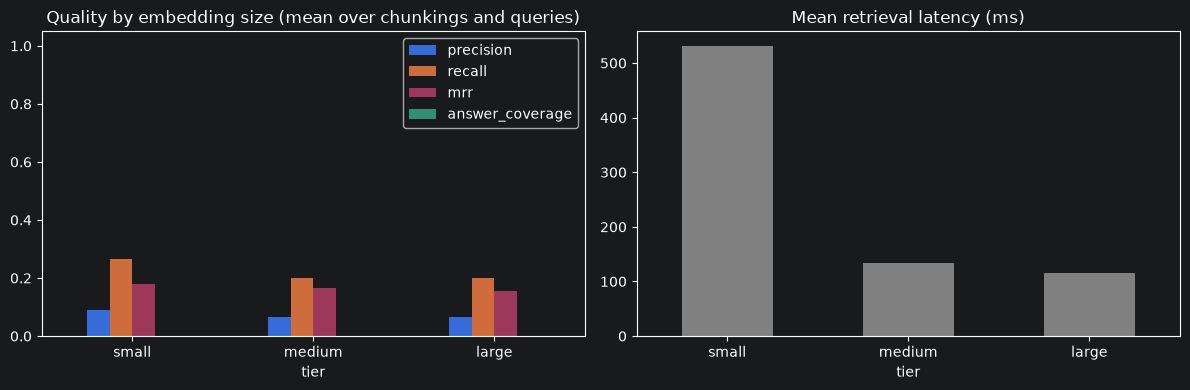

medium vs small (MRR, 15 chunking x query pairs): better 1, same 12, worse 2
large vs small (MRR, 15 chunking x query pairs): better 1, same 12, worse 2
large vs medium: better 0, same 14, worse 1


In [33]:
# ============================================================
# CELL 20: EMBEDDING SIZE VS RETRIEVAL AND ANSWER QUALITY
# ============================================================

metric_cols = ['precision', 'recall', 'mrr', 'answer_coverage']
by_emb = (results.groupby(['tier', 'dims'], sort=False)
          .agg(precision=('precision', 'mean'), recall=('recall', 'mean'), mrr=('mrr', 'mean'),
               answer_coverage=('answer_coverage', 'mean'), good_context=('context_label', lambda s: (s == 'Good').mean()),
               retrieval_ms=('retrieval_ms', 'mean'), generation_ms=('generation_ms', 'mean')).round(3))
display(by_emb)
display(results.pivot_table(index='tier', columns='strategy', values='mrr', sort=False).round(3)
        .style.set_caption('MRR by embedding model and chunking strategy'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
by_emb[metric_cols].reset_index(level=1, drop=True).plot.bar(ax=axes[0], rot=0)
axes[0].set_title('Quality by embedding size (mean over chunkings and queries)'); axes[0].set_ylim(0, 1.05)
by_emb['retrieval_ms'].reset_index(level=1, drop=True).plot.bar(ax=axes[1], rot=0, color='gray')
axes[1].set_title('Mean retrieval latency (ms)')
plt.tight_layout(); plt.show()

# Did larger always win? Compare large vs small and medium vs small for each (chunking, query) pair.
pairs = results.pivot_table(index=['strategy', 'qid'], columns='tier', values='mrr')
for bigger in ['medium', 'large']:
    diff = pairs[bigger] - pairs['small']
    print(f'{bigger} vs small (MRR, {len(diff)} chunking x query pairs): better {int((diff > 0).sum())}, '
          f'same {int((diff == 0).sum())}, worse {int((diff < 0).sum())}')
diff = pairs['large'] - pairs['medium']
print(f'large vs medium: better {int((diff > 0).sum())}, same {int((diff == 0).sum())}, worse {int((diff < 0).sum())}')

,precision,recall,mrr,answer_coverage,abstain_rate,prompt_tokens,generation_ms,n_chunks,mean_words
strategy,,,,,,,,,
fixed,0.089,0.267,0.178,0.0,0.0,488.067,8136.587,31,78.1
overlap,0.067,0.200,0.200,0.0,0.0,488.467,5516.417,49,76.2
hybrid,0.067,0.200,0.122,0.0,0.0,418.133,4657.043,52,46.6


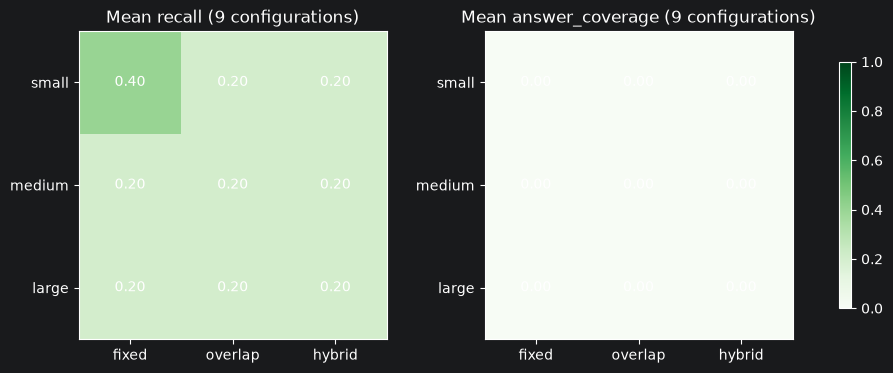

Best chunking per query (by mean MRR across the 3 embedding models):


strategy,fixed,hybrid,overlap
qid,,,
Q1,0.11,0.00,0.0
Q2,0.00,0.00,0.0
Q3,0.00,0.00,0.0
Q4,0.78,0.61,1.0
Q5,0.00,0.00,0.0


In [34]:
# ============================================================
# CELL 21: CHUNKING STRATEGY VS RETRIEVAL RELEVANCE AND ANSWERS
# ============================================================

by_chunk = (results.groupby('strategy', sort=False)
            .agg(precision=('precision', 'mean'), recall=('recall', 'mean'), mrr=('mrr', 'mean'),
                 answer_coverage=('answer_coverage', 'mean'), abstain_rate=('abstained', 'mean'),
                 prompt_tokens=('prompt_tokens', 'mean'), generation_ms=('generation_ms', 'mean')).round(3))
display(by_chunk.join(chunk_stats.set_index('strategy')[['n_chunks', 'mean_words']]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ['recall', 'answer_coverage']):
    grid = results.pivot_table(index='tier', columns='strategy', values=metric, sort=False)
    im = ax.imshow(grid.values, vmin=0, vmax=1, cmap='Greens')
    ax.set_xticks(range(grid.shape[1]), grid.columns); ax.set_yticks(range(grid.shape[0]), grid.index)
    for i in range(grid.shape[0]):
        for j in range(grid.shape[1]):
            ax.text(j, i, f'{grid.values[i, j]:.2f}', ha='center', va='center')
    ax.set_title(f'Mean {metric} (9 configurations)')
plt.colorbar(im, ax=axes, shrink=0.8); plt.show()

print('Best chunking per query (by mean MRR across the 3 embedding models):')
display(results.groupby(['qid', 'strategy'])['mrr'].mean().unstack().round(2))

EXTRA_DATA_PATH not set: the "larger dataset" condition is skipped (set it in CELL 3).


,,,precision,recall,mrr,noise,margin,retrieval_ms
corpus,paragraphs,chunks,,,,,,
subset 25% of other paragraphs,19,16,0.067,0.2,0.2,0.933,-0.282,22.786
subset 50% of other paragraphs,32,28,0.067,0.2,0.2,0.933,-0.315,12.664
full dataset,59,52,0.067,0.2,0.1,0.933,-0.098,38.250


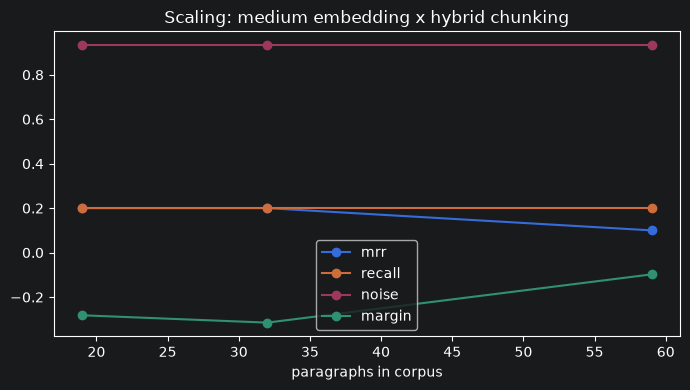

corpus,subset 25% of other paragraphs,subset 50% of other paragraphs,full dataset
qid,,,
Q1,0.0,0.0,0.0
Q2,0.0,0.0,0.0
Q3,0.0,0.0,0.0
Q4,1.0,1.0,0.5
Q5,0.0,0.0,0.0


In [35]:
# ============================================================
# CELL 22: SMALLER SUBSET VS FULL DATASET VS LARGER DATASET
# ============================================================

SCALING_TIER, SCALING_STRATEGY = 'medium', 'hybrid'   # TODO (team, optional): use your best configuration
SUBSET_FRACTIONS = [0.25, 0.5, 1.0]                     # share of the non-gold paragraphs kept

gold_pids = {p for q in TEST_QUERIES for p in q['relevant_paragraphs']}
others = [p for p in kb['pid'] if p not in gold_pids]
random.Random(SEED).shuffle(others)

corpora = {}
for frac in SUBSET_FRACTIONS:
    keep = gold_pids | set(others[:round(frac * len(others))])
    label = 'full dataset' if frac == 1.0 else f'subset {frac:.0%} of other paragraphs'
    corpora[label] = kb[kb['pid'].isin(keep)].reset_index(drop=True)
if EXTRA_DATA_PATH:
    extra = load_knowledge_base(EXTRA_DATA_PATH, pid_prefix='X')
    corpora['larger: full + extra data'] = pd.concat([kb, extra], ignore_index=True)
else:
    print('EXTRA_DATA_PATH not set: the "larger dataset" condition is skipped (set it in CELL 3).')

scaling_rows = []
for label, corpus in corpora.items():
    store = VectorStore(SCALING_TIER, SCALING_STRATEGY, CHUNKERS[SCALING_STRATEGY](corpus))
    for q in TEST_QUERIES:
        hits, ms = store.search(q['query'], k=TOP_K)
        rm = retrieval_metrics(hits, q['relevant_paragraphs'])
        wide, _ = store.search(q['query'], k=20)              # wider list to measure the margin
        rel = [h['score'] for h in wide if set(h['pids']) & set(q['relevant_paragraphs'])]
        irr = [h['score'] for h in wide if not set(h['pids']) & set(q['relevant_paragraphs'])]
        scaling_rows.append({'corpus': label, 'paragraphs': len(corpus), 'chunks': len(store.chunks),
                             'qid': q['qid'], 'precision': rm['precision'], 'recall': rm['recall'], 'mrr': rm['mrr'],
                             'noise': 1 - rm['precision'],
                             'margin': (max(rel) - max(irr)) if rel and irr else np.nan, 'retrieval_ms': ms})

scaling = pd.DataFrame(scaling_rows)
scaling_summary = scaling.groupby(['corpus', 'paragraphs', 'chunks'], sort=False)[
    ['precision', 'recall', 'mrr', 'noise', 'margin', 'retrieval_ms']].mean().round(3)
display(scaling_summary)

ax = scaling_summary.reset_index().plot(x='paragraphs', y=['mrr', 'recall', 'noise', 'margin'], marker='o', figsize=(7, 4))
ax.set_title(f'Scaling: {SCALING_TIER} embedding x {SCALING_STRATEGY} chunking'); ax.set_xlabel('paragraphs in corpus')
plt.tight_layout(); plt.show()
display(scaling.pivot_table(index='qid', columns='corpus', values='mrr', sort=False).round(2))

In [36]:
# ============================================================
# CELL 23: HALLUCINATION TEST WITH THE OUT-OF-SCOPE QUERY
# ============================================================

oos_rows = []
for (tier, strategy), store in STORES.items():
    res = rag_answer(OUT_OF_SCOPE_QUERY, store)
    oos_rows.append({'tier': tier, 'dims': store.dim, 'strategy': strategy, 'qid': 'OOS', 'query': OUT_OF_SCOPE_QUERY,
                     'hits': res['hits'], 'answer': res['answer'], 'abstained': answer_metrics(res['answer'], ['x'])['abstained'],
                     'top_score': res['hits'][0]['score']})
oos = pd.DataFrame(oos_rows)
display(oos[['tier', 'strategy', 'top_score', 'abstained', 'answer']])
print(f"Model abstained correctly in {oos['abstained'].sum()}/{len(oos)} configurations.")

,tier,strategy,top_score,abstained,answer
0,small,fixed,0.295696,True,I don't know based on the provided documents.
1,small,overlap,0.295696,True,I don't know based on the provided documents.
2,small,hybrid,0.295623,True,I don't know based on the provided documents.
3,medium,fixed,0.273993,True,I don't know based on the provided documents.
4,medium,overlap,0.273993,True,I don't know based on the provided documents.
5,medium,hybrid,0.293825,True,I don't know based on the provided documents.
6,large,fixed,0.787258,True,I don't know based on the provided documents.
7,large,overlap,0.787258,True,I don't know based on the provided documents.
8,large,hybrid,0.792600,True,I don't know based on the provided documents.


Model abstained correctly in 9/9 configurations.


In [37]:
# ============================================================
# CELL 24: SELECT AND SHOW AT LEAST 3 FAILURE CASES
# ============================================================

N_FAILURES = 3
kb_text = dict(zip(kb['pid'], kb['text']))

def failure_type(r):
    if r.get('qid') == 'OOS':
        return 'hallucinated answer to an out-of-scope question'
    if r['context_label'] == 'Poor':
        return 'wrong chunks retrieved'
    if r['context_label'] == 'Partial' and r['missed_pids']:
        return 'incomplete context'
    if r['answer_label'] != 'Good':
        return 'incorrect / incomplete answer despite usable context'
    return 'weak ranking'

# Severity: no relevant chunk > missing gold paragraph > poor answer > low MRR.
ranked = results.assign(severity=(results['context_label'] == 'Poor') * 4 + (results['recall'] < 1) * 2
                        + (results['answer_label'] == 'Poor') * 2 + (1 - results['mrr']) + (1 - results['answer_coverage']))
ranked = ranked[ranked['severity'] > 0].sort_values('severity', ascending=False)

# Pass 1: new query AND new failure type; pass 2: new query; pass 3: any remaining configuration.
failures, used_q, used_types, used_rows = [], set(), set(), set()
for pass_no in (1, 2, 3):
    for idx, r in ranked.iterrows():
        ftype = failure_type(r)
        if len(failures) >= N_FAILURES or idx in used_rows:
            continue
        if (pass_no < 3 and r['qid'] in used_q) or (pass_no == 1 and ftype in used_types):
            continue
        failures.append({**r.to_dict(), 'failure_type': ftype})
        used_rows.add(idx); used_q.add(r['qid']); used_types.add(ftype)
for _, r in oos[~oos['abstained']].head(1).iterrows():    # add a hallucination case if one occurred
    failures.append({**r.to_dict(), 'failure_type': failure_type(r), 'relevant_flags': [False] * len(r['hits']),
                     'context_label': 'n/a', 'answer_label': 'Poor', 'recall': np.nan, 'mrr': np.nan, 'missed_pids': []})
if len(failures) < N_FAILURES:
    print(f'Only {len(failures)} failures found. Add harder queries (paraphrases, multi-paragraph, vague) in CELL 15.')

for i, f in enumerate(failures, 1):
    print(f"\n{'#' * 100}\nFAILURE {i}: {f['failure_type'].upper()}\n{'#' * 100}")
    print(f"Configuration : {f['tier']} embedding x {f['strategy']} chunking")
    print(f"Query         : {f['qid']}: {f['query']}")
    if f['qid'] != 'OOS':
        q = next(t for t in TEST_QUERIES if t['qid'] == f['qid'])
        print(f"Context: {f['context_label']} (recall {f['recall']:.2f}, MRR {f['mrr']:.2f}) | Answer: {f['answer_label']}")
        print('Gold paragraph(s) that SHOULD have been retrieved:')
        for p in q['relevant_paragraphs']:
            print(f'   {p}: {kb_text[p][:250]}...')
    print('Retrieved chunks:')
    print(format_hits(f['hits'], f['relevant_flags']))
    print(f"Answer: {f['answer']}")


####################################################################################################
FAILURE 1: WRONG CHUNKS RETRIEVED
####################################################################################################
Configuration : medium embedding x overlap chunking
Query         : Q3: When are spinach seedlings ready to transplant, and what signs show they’re ready?
Context: Poor (recall 0.00, MRR 0.00) | Answer: Poor
Gold paragraph(s) that SHOULD have been retrieved:
   P004: - Choose the type and size (diameter) of pot or polybag to suit the plant being grown. - For perennial plants, generally fruit plants, choose a pot made from a drum/can or a pot with a diameter of about 60 cm. - For medicinal plants or vegetables, a ...
Retrieved chunks:
[1] (0.633) OVL-015 ['P024', 'P029']: Spinach is propagated from seed. Some recommended varieties include: Giti Hijau, Giti Merah, Kakap Hijau, Bangkok, and Cimangkok. When the sown seedlings are about 12 days old, the...
[

In [38]:
# ============================================================
# CELL 25: ROOT-CAUSE EVIDENCE FOR EACH FAILURE
# ============================================================

# TODO (team, optional): your own improved wording for specific queries, e.g. {'Q3': 'better query ...'}
QUERY_REWRITES = {}

REWRITE_PROMPT = (f'You rewrite user questions into precise search queries for a document collection about {KB_DESCRIPTION}. '
                  'Keep the meaning, expand abbreviations, add the key terms a relevant document would use. '
                  'Return ONLY the rewritten query on one line.')

def rewrite_query(qid, query):
    if qid in QUERY_REWRITES:
        return QUERY_REWRITES[qid]
    out = generator.generate([{'role': 'system', 'content': REWRITE_PROMPT}, {'role': 'user', 'content': query}], 60)
    return out.splitlines()[0].strip().strip('"') if out.strip() else query

def diagnose(f):
    if f['qid'] == 'OOS':
        return {'likely cause': 'generation / prompt',
                'evidence': f"answer is not supported by the documents (top score {f['hits'][0]['score']:.2f}); the prompt did not make the model abstain"}
    q = next(t for t in TEST_QUERIES if t['qid'] == f['qid'])
    same_q = results[results['qid'] == f['qid']]
    better_chunking = same_q[(same_q['tier'] == f['tier']) & (same_q['strategy'] != f['strategy']) & (same_q['mrr'] > f['mrr'])]
    better_embedding = same_q[(same_q['strategy'] == f['strategy']) & (same_q['tier'] != f['tier']) & (same_q['mrr'] > f['mrr'])]
    rewritten = rewrite_query(f['qid'], f['query'])
    rw_hits, _ = STORES[(f['tier'], f['strategy'])].search(rewritten, k=TOP_K)
    rw = retrieval_metrics(rw_hits, q['relevant_paragraphs'])
    causes, evidence = [], []
    if f['context_label'] == 'Good' and f['answer_label'] != 'Good':
        causes.append('generation / prompt'); evidence.append('context contained the gold paragraph but the answer missed key facts')
    if len(better_chunking):
        causes.append('chunking'); evidence.append(f"same model, other chunking: {dict(zip(better_chunking['strategy'], better_chunking['mrr'].round(2)))} vs {f['mrr']:.2f}")
    if len(better_embedding):
        causes.append('embedding model'); evidence.append(f"same chunking, other model: {dict(zip(better_embedding['tier'], better_embedding['mrr'].round(2)))} vs {f['mrr']:.2f}")
    if rw['mrr'] > f['mrr']:
        causes.append('query formulation'); evidence.append(f"rewritten query '{rewritten}' -> MRR {rw['mrr']:.2f} (was {f['mrr']:.2f})")
    if not causes:
        causes.append('data / query ambiguity'); evidence.append(f"no single change fixed it (rewrite tried: '{rewritten}')")
    return {'likely cause': ' + '.join(causes), 'evidence': ' | '.join(evidence)}

root_causes = pd.DataFrame([{'failure': i, 'config': f"{f['tier']} x {f['strategy']}", 'query': f"{f['qid']}: {f['query']}",
                             'failure type': f['failure_type'], **diagnose(f)} for i, f in enumerate(failures, 1)])
with pd.option_context('display.max_colwidth', None):
    display(root_causes)

,failure,config,query,failure type,likely cause,evidence
0,1,medium x overlap,"Q3: When are spinach seedlings ready to transplant, and what signs show they’re ready?",wrong chunks retrieved,data / query ambiguity,no single change fixed it (rewrite tried: 'When are spinach seedlings ready for transplantation and what are the indicators of readiness?')
1,2,large x hybrid,Q4: What spacing and pot size does the guide recommend for tomatoes grown in beds versus polybags or pots?,incorrect / incomplete answer despite usable context,chunking + embedding model + query formulation,"same model, other chunking: {'fixed': 1.0, 'overlap': 1.0} vs 0.33 | same chunking, other model: {'small': 1.0, 'medium': 0.5} vs 0.33 | rewritten query 'Spacing and pot size recommendations for tomatoes grown in beds versus polybags or pots in gardening knowledge base' -> MRR 1.00 (was 0.33)"
2,3,medium x overlap,"Q1: What growing medium mix should be used for pots, polybags, and vertical gardens?",wrong chunks retrieved,data / query ambiguity,"no single change fixed it (rewrite tried: 'Growing medium mix for pots, polybags, and vertical gardens')"


In [39]:
# ============================================================
# CELL 26: BEFORE VS AFTER
# ============================================================

IMPROVED_SYSTEM_PROMPT = (
    f'You are a careful assistant that answers questions about {KB_DESCRIPTION}.\n'
    'Rules:\n'
    '1. Use ONLY facts stated in the numbered context. Do not use outside knowledge.\n'
    '2. Cite the chunk numbers you used, e.g. [1] or [2][3].\n'
    '3. If the context answers only part of the question, answer that part and say what is missing.\n'
    "4. If no chunk is relevant, reply exactly: I don't know based on the provided documents.\n"
    '5. Answer in 2-4 sentences.'
)

target = failures[0] if failures else results.sort_values('mrr').iloc[0].to_dict()
T_TIER, T_STRATEGY = target['tier'], target['strategy']     # TODO (team, optional): choose another configuration
print(f'Improving configuration: {T_TIER} embedding x {T_STRATEGY} chunking')

LARGER_CHUNKERS = {
    'fixed':   lambda data: fixed_length_chunks(data, max_words=int(FIXED_CHUNK_WORDS * 1.75)),
    'overlap': lambda data: overlapping_paragraph_chunks(data, window=3, stride=1),
    'hybrid':  lambda data: hybrid_chunks(data, get_encoder('small'), max_words=int(HYBRID_MAX_WORDS * 1.5), merge_sim=0.55),
}
base_store = STORES[(T_TIER, T_STRATEGY)]
larger_store = VectorStore(T_TIER, T_STRATEGY, LARGER_CHUNKERS[T_STRATEGY](kb))

VARIANTS = {
    'baseline':        dict(store=base_store,   k=TOP_K, prompt=SYSTEM_PROMPT,          rewrite=False),
    'top-k = 5':       dict(store=base_store,   k=5,     prompt=SYSTEM_PROMPT,          rewrite=False),
    'improved prompt': dict(store=base_store,   k=TOP_K, prompt=IMPROVED_SYSTEM_PROMPT, rewrite=False),
    'query rewrite':   dict(store=base_store,   k=TOP_K, prompt=SYSTEM_PROMPT,          rewrite=True),
    'larger chunks':   dict(store=larger_store, k=TOP_K, prompt=SYSTEM_PROMPT,          rewrite=False),
    'combined':        dict(store=base_store,   k=5,     prompt=IMPROVED_SYSTEM_PROMPT, rewrite=True),
}

rewrites = {q['qid']: rewrite_query(q['qid'], q['query']) for q in TEST_QUERIES}
improve_rows = []
for vname, v in VARIANTS.items():
    for q in TEST_QUERIES + [{'qid': 'OOS', 'query': OUT_OF_SCOPE_QUERY, 'relevant_paragraphs': [], 'expected_keywords': []}]:
        search_q = rewrites.get(q['qid'], q['query']) if v['rewrite'] else q['query']
        hits, r_ms = v['store'].search(search_q, k=v['k'])
        messages = build_prompt(q['query'], hits, v['prompt'])      # the LLM always sees the user's original question
        t0 = time.perf_counter(); answer = generator.generate(messages); g_ms = (time.perf_counter() - t0) * 1000
        row = {'variant': vname, 'qid': q['qid'], 'search_query': search_q, 'answer': answer, 'hits': hits,
               'latency_ms': r_ms + g_ms, 'prompt_tokens': generator.count_tokens(messages)}
        if q['qid'] == 'OOS':
            row['oos_abstained'] = answer_metrics(answer, ['x'])['abstained']
        else:
            row.update({k: val for k, val in retrieval_metrics(hits, q['relevant_paragraphs']).items() if k in ('precision', 'recall', 'mrr')})
            row.update({k: val for k, val in answer_metrics(answer, q['expected_keywords']).items() if k in ('answer_coverage', 'abstained')})
        improve_rows.append(row)
improve = pd.DataFrame(improve_rows)
improve['oos_abstained'] = improve['oos_abstained'].astype(float)

summary = improve.groupby('variant', sort=False).agg(
    precision=('precision', 'mean'), recall=('recall', 'mean'), mrr=('mrr', 'mean'),
    answer_coverage=('answer_coverage', 'mean'), oos_abstained=('oos_abstained', 'max'),
    latency_ms=('latency_ms', 'mean'), prompt_tokens=('prompt_tokens', 'mean')).round(3)
display(summary.style.highlight_max(subset=['recall', 'mrr', 'answer_coverage'], color='#c6efce'))

Improving configuration: medium embedding x overlap chunking


,precision,recall,mrr,answer_coverage,oos_abstained,latency_ms,prompt_tokens
variant,,,,,,,
baseline,0.067000,0.200000,0.200000,0.000000,1.000000,6127.653000,451.333000
top-k = 5,0.040000,0.200000,0.200000,0.000000,1.000000,8330.073000,743.167000
improved prompt,0.067000,0.200000,0.200000,0.000000,1.000000,6335.442000,506.333000
query rewrite,0.067000,0.200000,0.100000,0.000000,1.000000,5184.985000,424.667000
larger chunks,0.067000,0.200000,0.200000,0.000000,1.000000,6063.228000,573.667000
combined,0.080000,0.200000,0.100000,0.000000,1.000000,6993.046000,785.667000


In [40]:
# ============================================================
# CELL 27: BEFORE VS AFTER FOR THE FAILED QUERIES
# ============================================================

# TODO (team): set the variant you choose as your fix.
CHOSEN_FIX = summary.drop('baseline')['answer_coverage'].idxmax()
print('Chosen fix:', CHOSEN_FIX)

failed_qids = [f['qid'] for f in failures if f['tier'] == T_TIER and f['strategy'] == T_STRATEGY] or \
              list(improve[(improve.variant == 'baseline') & (improve.qid != 'OOS')].sort_values('mrr')['qid'][:2])
for qid in dict.fromkeys(failed_qids + ['OOS']):
    print(f"\n{'=' * 100}\n{qid}: {next((t['query'] for t in TEST_QUERIES if t['qid'] == qid), OUT_OF_SCOPE_QUERY)}")
    for vname in ['baseline', CHOSEN_FIX]:
        r = improve[(improve.variant == vname) & (improve.qid == qid)].iloc[0]
        scores = 'abstained' if qid == 'OOS' and r['oos_abstained'] else \
                 ('answered (no abstention)' if qid == 'OOS' else f"recall {r['recall']:.2f}, MRR {r['mrr']:.2f}, keywords {r['answer_coverage']:.0%}")
        print(f"\n--- {vname.upper()} | {scores}")
        if r['search_query'] != next((t['query'] for t in TEST_QUERIES if t['qid'] == qid), OUT_OF_SCOPE_QUERY):
            print('    search query:', r['search_query'])
        print('    chunks:', [(h['chunk_id'], h['pids'], round(h['score'], 3)) for h in r['hits']])
        print('    answer:', r['answer'])

before, after = summary.loc['baseline'], summary.loc[CHOSEN_FIX]
display(pd.DataFrame({'before (baseline)': before, f'after ({CHOSEN_FIX})': after, 'change': after - before}).round(3))

Chosen fix: top-k = 5

Q3: When are spinach seedlings ready to transplant, and what signs show they’re ready?

--- BASELINE | recall 0.00, MRR 0.00, keywords 0%
    chunks: [('OVL-015', ['P024', 'P029'], 0.633), ('OVL-030', ['P021', 'P027'], 0.614), ('OVL-013', ['P015', 'P016'], 0.587)]
    answer: Spinach seedlings are generally ready to transplant at 7–15 days old, depending on the type of plant. They are ready when they show good growth and have at least 3 true leaves.

--- TOP-K = 5 | recall 0.00, MRR 0.00, keywords 0%
    chunks: [('OVL-015', ['P024', 'P029'], 0.633), ('OVL-030', ['P021', 'P027'], 0.614), ('OVL-013', ['P015', 'P016'], 0.587), ('OVL-012', ['P014', 'P015'], 0.561), ('OVL-022', ['P019', 'P026'], 0.534)]
    answer: Spinach seedlings are ready to transplant at 7–15 days old, depending on the type of plant. They are ready when they show good growth and have at least 3 true leaves.

Q1: What growing medium mix should be used for pots, polybags, and vertical gardens?

--

,before (baseline),after (top-k = 5),change
precision,0.067,0.040,-0.027
recall,0.200,0.200,0.000
mrr,0.200,0.200,0.000
answer_coverage,0.000,0.000,0.000
oos_abstained,1.000,1.000,0.000
latency_ms,6127.653,8330.073,2202.420
prompt_tokens,451.333,743.167,291.834


,tier,dims,strategy,prompt_tokens,retrieval_ms,generation_ms,n_chunks,mean_chunk_words,index_KB,embed_time_s,index_MB_per_1M_chunks
0,small,384,fixed,482.6,1275.2,14645.4,31,78.1,46.5,0.36,1465.0
1,small,384,overlap,488.2,209.8,5802.8,49,76.2,73.5,0.19,1465.0
2,small,384,hybrid,398.6,109.5,4147.5,52,46.6,78.0,0.48,1465.0
3,medium,768,fixed,487.8,134.2,4436.9,31,78.1,93.0,0.69,2930.0
4,medium,768,overlap,480.6,122.7,5244.2,49,76.2,147.0,1.13,2930.0
5,medium,768,hybrid,457.2,142.2,5334.5,52,46.6,156.0,0.82,2930.0
6,large,1024,fixed,493.8,116.7,5327.5,31,78.1,124.0,1.76,3906.0
7,large,1024,overlap,496.6,99.9,5502.2,49,76.2,196.0,2.65,3906.0
8,large,1024,hybrid,398.6,129.4,4489.1,52,46.6,208.0,2.29,3906.0


,top_k,mean_prompt_tokens,generation_ms (Q1)
0,1,210.4,5893.5
1,3,457.2,7560.5
2,5,596.8,6077.8
3,8,817.8,7572.0


top-k=1: ~10.5M input tokens/day = $5.26/day at $0.5/1M tokens
top-k=3: ~22.9M input tokens/day = $11.43/day at $0.5/1M tokens
top-k=5: ~29.8M input tokens/day = $14.92/day at $0.5/1M tokens
top-k=8: ~40.9M input tokens/day = $20.45/day at $0.5/1M tokens


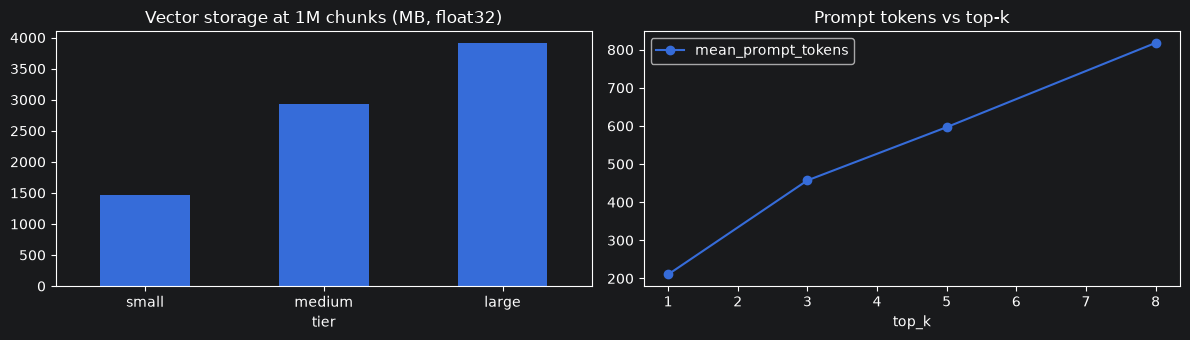

In [41]:
# ============================================================
# CELL 28: MEASURED COST DRIVERS (EMBEDDING SIZE, CHUNK SIZE, TOP-K)
# ============================================================

cost = (results.groupby(['tier', 'dims', 'strategy'], sort=False)
        .agg(prompt_tokens=('prompt_tokens', 'mean'), retrieval_ms=('retrieval_ms', 'mean'),
             generation_ms=('generation_ms', 'mean')).round(1).reset_index())
cost['n_chunks'] = [len(CHUNKS[s]) for s in cost['strategy']]
cost['mean_chunk_words'] = [chunk_stats.set_index('strategy').loc[s, 'mean_words'] for s in cost['strategy']]
cost['index_KB'] = [round(STORES[(t, s)].vectors.nbytes / 1024, 1) for t, s in zip(cost['tier'], cost['strategy'])]
cost['embed_time_s'] = [round(STORES[(t, s)].build_s, 2) for t, s in zip(cost['tier'], cost['strategy'])]
cost['index_MB_per_1M_chunks'] = (cost['dims'] * 4 * 1e6 / 1024 ** 2).round(0)   # float32 storage at 1M chunks
display(cost)

# Top-k sweep: prompt size and generation latency grow with k.
K_VALUES = [1, 3, 5, 8]
sweep_store = STORES[('medium', 'hybrid')]
sweep = []
for k in K_VALUES:
    toks = [generator.count_tokens(build_prompt(q['query'], sweep_store.search(q['query'], k)[0])) for q in TEST_QUERIES]
    t0 = time.perf_counter(); generator.generate(build_prompt(TEST_QUERIES[0]['query'], sweep_store.search(TEST_QUERIES[0]['query'], k)[0]))
    sweep.append({'top_k': k, 'mean_prompt_tokens': np.mean(toks), 'generation_ms (Q1)': (time.perf_counter() - t0) * 1000})
sweep = pd.DataFrame(sweep).round(1)
display(sweep)

# TODO (team, optional): price per 1M input tokens if the generator were a paid API.
PRICE_PER_1M_INPUT_TOKENS = 0.50
QUERIES_PER_DAY = 10_000 * 5          # 10K users x ~5 questions
for _, r in sweep.iterrows():
    print(f"top-k={int(r.top_k)}: ~{r.mean_prompt_tokens * QUERIES_PER_DAY / 1e6:.1f}M input tokens/day "
          f"= ${r.mean_prompt_tokens * QUERIES_PER_DAY / 1e6 * PRICE_PER_1M_INPUT_TOKENS:.2f}/day at ${PRICE_PER_1M_INPUT_TOKENS}/1M tokens")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
cost.groupby('tier', sort=False)['index_MB_per_1M_chunks'].first().plot.bar(ax=axes[0], rot=0, title='Vector storage at 1M chunks (MB, float32)')
sweep.plot(x='top_k', y='mean_prompt_tokens', marker='o', ax=axes[1], title='Prompt tokens vs top-k')
plt.tight_layout(); plt.show()

In [42]:
# ============================================================
# CELL 29: SUMMARY OF THE RUN AND SAVED FILES
# ============================================================

best = results.groupby(['tier', 'strategy'])[['mrr', 'recall', 'answer_coverage']].mean().sort_values(['mrr', 'answer_coverage'], ascending=False)
print('Generation model (fixed):', GEN_MODEL_NAME)
print(f'Knowledge base: {len(kb)} paragraphs, {int(kb.n_words.sum()):,} words | test queries: {len(TEST_QUERIES)} | top-k: {TOP_K}')
print('\nConfigurations ranked by MRR, then answer keyword coverage:')
display(best.round(3))
print('\nSaved files:')
for p in sorted(ROOT.rglob('*')):
    if p.is_file():
        print(f'  {str(p.relative_to(ROOT)):45} {p.stat().st_size:>12,} bytes')

Generation model (fixed): Qwen/Qwen2.5-3B-Instruct
Knowledge base: 59 paragraphs, 2,422 words | test queries: 5 | top-k: 3

Configurations ranked by MRR, then answer keyword coverage:


mrr  recall  answer_coverage
tier   strategy                                
large  fixed     0.200     0.2              0.0
       overlap   0.200     0.2              0.0
medium fixed     0.200     0.2              0.0
       overlap   0.200     0.2              0.0
small  hybrid    0.200     0.2              0.0
       overlap   0.200     0.2              0.0
       fixed     0.133     0.4              0.0
medium hybrid    0.100     0.2              0.0
large  hybrid    0.067     0.2              0.0


Saved files:
  __init__.py                                              0 bytes
  evaluation_table.csv                                55,494 bytes
  experiment_results.pkl                              59,751 bytes
  retrieved_chunks_report.md                          86,746 bytes
  vectors/large_fixed.json                            18,251 bytes
  vectors/large_fixed.npz                            118,317 bytes
  vectors/large_hybrid.json                           21,333 bytes
  vectors/large_hybrid.npz                           198,141 bytes
  vectors/large_overlap.json                          28,203 bytes
  vectors/large_overlap.npz                          186,743 bytes
  vectors/medium_fixed.json                           18,270 bytes
  vectors/medium_fixed.npz                            89,076 bytes
  vectors/medium_hybrid.json                          21,352 bytes
  vectors/medium_hybrid.npz                          149,109 bytes
  vectors/medium_overlap.json                   